In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from eo_toolkit import (
    load_cached_sentinel1_as_numpy_tensor,
    correlated_seasonal_mann_kendall,
    compute_monthly_median,
    compute_patch_series,
    compute_residuals,
)

In [3]:
romeyer = "sentinel1_lat_44.7817_lon_5.4215_size_1000"
justin = "sentinel1_lat_44.7401_lon_5.3502019_size_2000"

path_to_data = Path("../data") / justin

sentinel1_data = load_cached_sentinel1_as_numpy_tensor(path_to_data)

In [4]:
s1_vv_vh_bands = sentinel1_data["bands"]  # (time, bands, depth, width), e.g., (482, 2, 103, 103)
dates = sentinel1_data["dates"]           # (time, )
orbits = sentinel1_data["orbits"]         # (time, )

In [5]:
df = compute_patch_series(s1_vv_vh_bands, dates)

## Mann-Kendall test

In [6]:
def plot_time_series(s: pd.Series, title: str, ylabel: str) -> None:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(s.index, s.values, marker="o", linestyle="-", markersize=3, color="tab:blue", alpha=0.8)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_xlabel("Date", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


--- vh_db ---
  trend: no trend
  p: 0.701
  sen_slope_per_year: 0.002
  n_months: 140


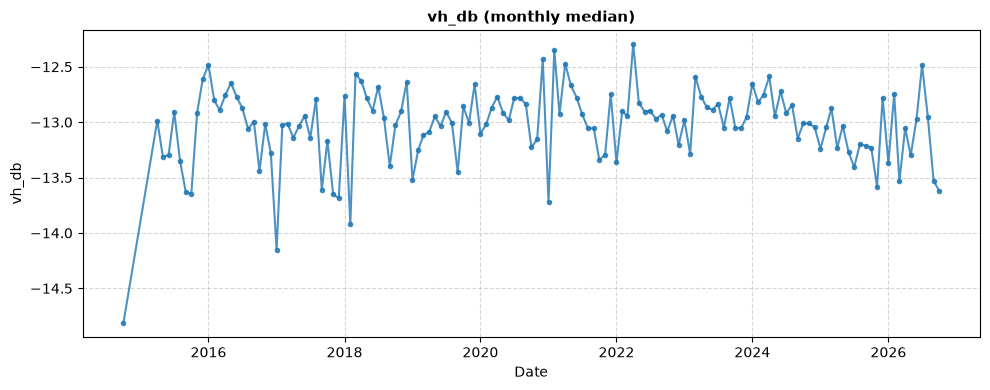


--- vv_db ---
  trend: no trend
  p: 0.235
  sen_slope_per_year: 0.014
  n_months: 140


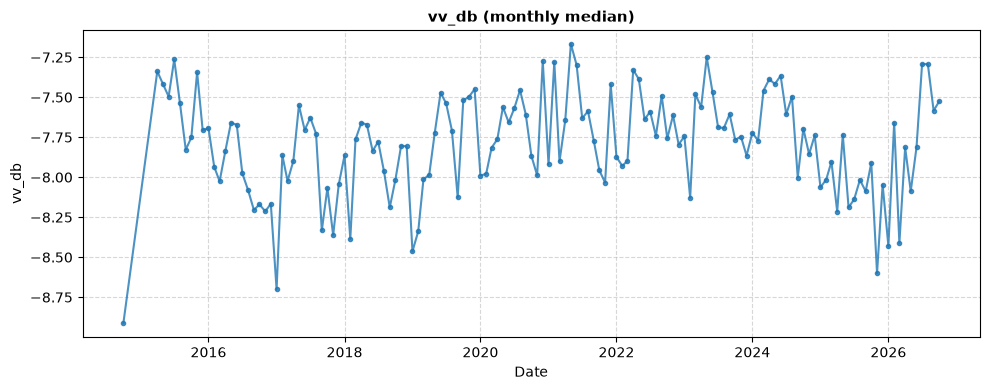


--- ratio_db ---
  trend: no trend
  p: 0.224
  sen_slope_per_year: -0.003
  n_months: 140


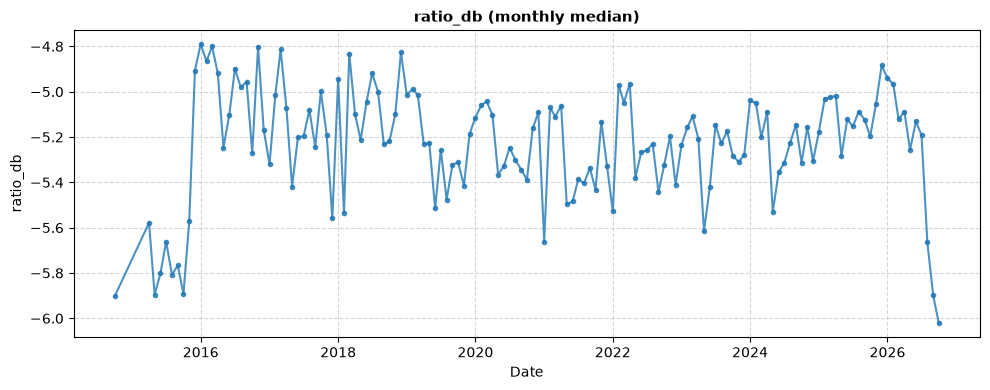


--- rvi ---
  trend: no trend
  p: 0.224
  sen_slope_per_year: -0.000
  n_months: 140


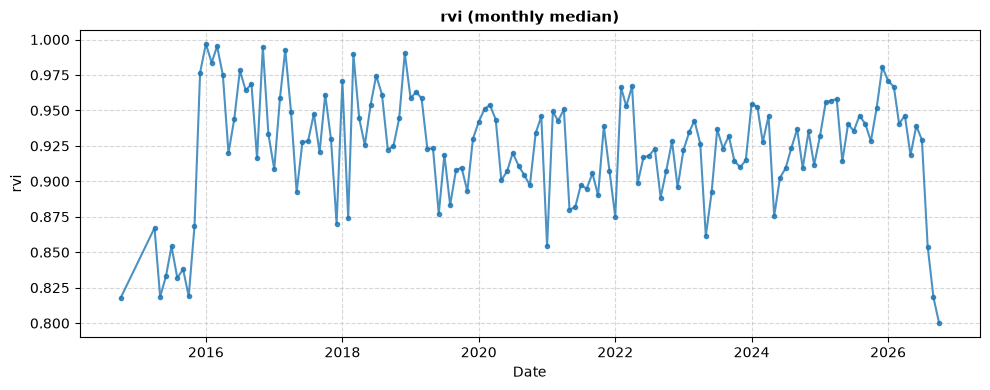

In [7]:
for col in ("vh_db", "vv_db", "ratio_db", "rvi"):
    s = compute_monthly_median(df, col)
    res = correlated_seasonal_mann_kendall(s)
    
    print(f"\n--- {col} ---")
    for key, val in res.items():
        if isinstance(val, float):
            print(f"  {key}: {val:.3f}")
        else:
            print(f"  {key}: {val}")
            
    plot_time_series(s, title=f"{col} (monthly median)", ylabel=col)

## Residual analysis (de-seasoning and de-trending)

In [8]:
def plot_residuals(residuals: pd.Series, title: str, ylabel: str) -> None:
    """Plots a de-seasoned and de-trended residual time series."""
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(residuals.index, residuals.values, marker="o", linestyle="-", color="tab:orange", markersize=3, alpha=0.8)
    ax.axhline(0, color="black", linestyle="--", linewidth=1, alpha=0.7)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_xlabel("Date", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

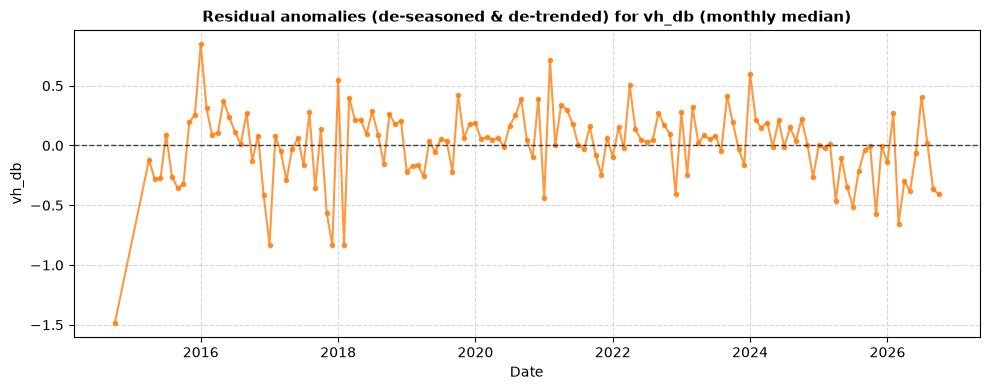

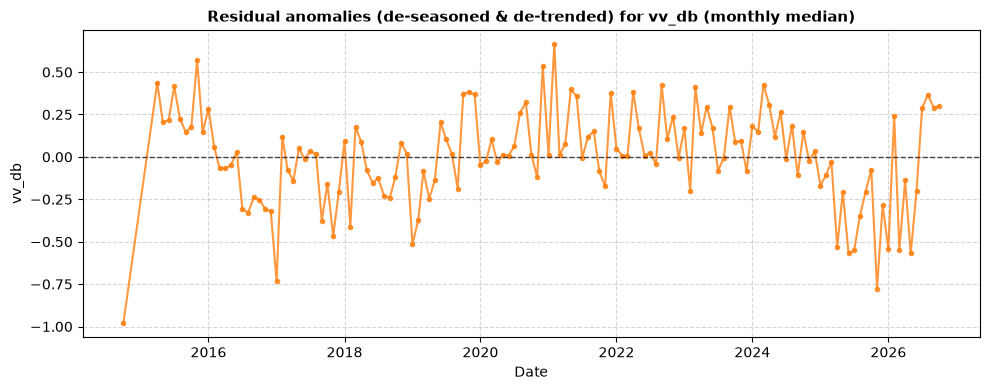

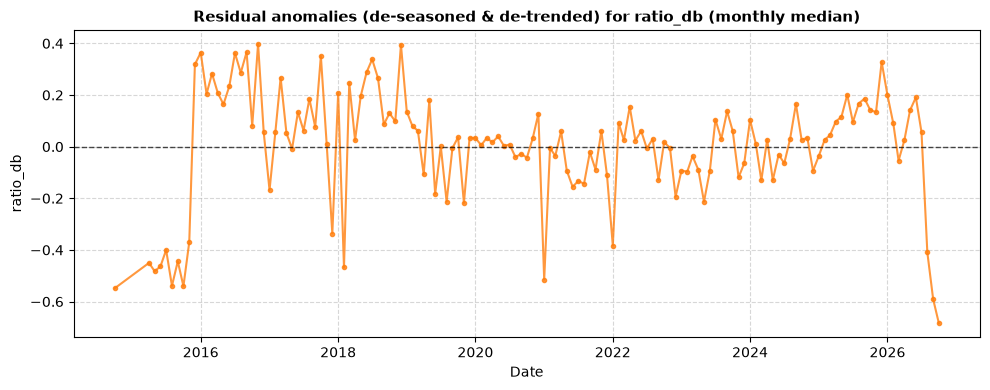

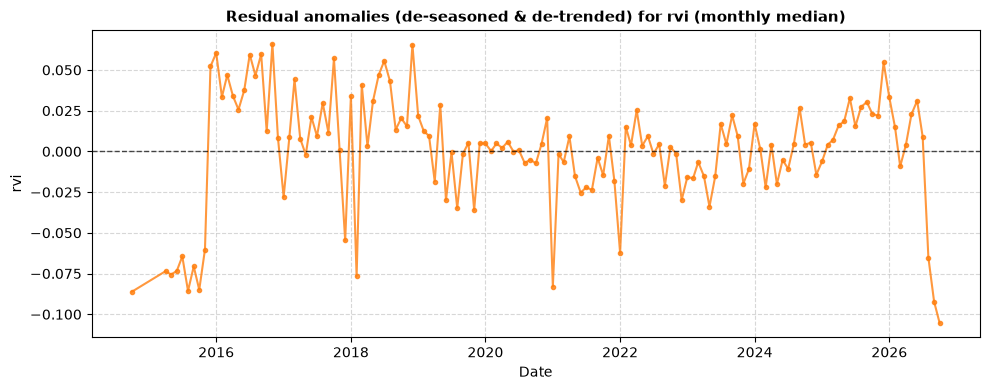

In [9]:
for col in ("vh_db", "vv_db", "ratio_db", "rvi"):
    s = compute_monthly_median(df, col)
    residuals = compute_residuals(s)
    plot_residuals(residuals, title=f"Residual anomalies (de-seasoned & de-trended) for {col} (monthly median)", ylabel=col)